# $\zeta(5)$: historical constructions and new result

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

**Run status:**

- New ${}_8F_7(1)$ trajectory: Depth-500 attempt stopped after 480 seconds.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    brown_zudilin_seeds, numerical_dual_walk, zudilin_zeta5_hypergeometric_readout,
    zudilin_zeta5_hypergeometric_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x = sp.symbols('x0:8')
y = sp.symbols('y0:7')
target = lambda: arb(5).zeta()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Zudilin (2002): full hypergeometric CMF

[equations (7), (15), and Theorem 1](https://arxiv.org/abs/math/0206178).

**CMF:** ${}_8F_7(1)$, rank 7, with all 15 parameter axes.
**Start:** $(8,3,3,3,3,3,3,3;6,6,6,6,6,6,6)$.
**Direction:** $(3,1,1,1,1,1,1,1;2,2,2,2,2,2,2)$.
Source index N uses N−2 steps. **Readout:** the exact coefficient-minor ratio in `zudilin_zeta5_hypergeometric_readout`.

In [5]:
cmf = pFq(8, 7, 1)
start = dict(zip(x + y, [8] + [3] * 7 + [6] * 7))
trajectory = dict(zip(x + y, [3] + [1] * 7 + [2] * 7))
seeds = zudilin_zeta5_hypergeometric_seeds()
walks = cmf.walk(trajectory, [N - 2 for N in DEPTHS], start)
approximants = [zudilin_zeta5_hypergeometric_readout(W, N, seeds) for N, W in zip(DEPTHS, walks)]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zudilin (2002)'] = (DEPTHS, deltas)
accuracy['Zudilin (2002)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.219575829822


## 2. Brown–Zudilin (2022)

[Preprint](https://arxiv.org/abs/2210.03391).

**CMF:** ${}_8F_7(1)$ · **Start:** $(5,2,2,2,2,2,2,2;4,4,4,4,4,4,4)$ ·
**Direction:** $(41,17,16,15,14,13,12,11;24,25,26,27,28,29,30)$.
We use the inverse-transpose walk and the exact two-row projection stored
with the original construction.

In [7]:
cmf = pFq(8, 7, 1)
start = dict(zip(x + y, [5, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4]))
trajectory = dict(zip(x + y, [41, 17, 16, 15, 14, 13, 12, 11, 24, 25, 26, 27, 28, 29, 30]))
P, Q = brown_zudilin_seeds()
walks = numerical_dual_walk(cmf, trajectory, DEPTHS, start)
approximants = [sum((c * W[j, 0]
                for j, c in enumerate(P))) / sum((c * W[j, 0] for j, c in enumerate(Q))) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Brown–Zudilin (2022)'] = (DEPTHS, deltas)
accuracy['Brown–Zudilin (2022)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.132809517641


## 3. New ${}_8F_7(1)$ trajectory

[New Directions in Irrationality](https://arxiv.org/abs/2610.27799).

**CMF:** dual ${}_8F_7(1)$, rank 7.
**Start:** $(5,2,2,2,2,2,2,2;4,4,4,4,4,4,4)$.
**Direction:** $(164,67,63,59,56,52,48,44;97,101,105,108,112,116,120)$.
**Readout:** the Brown–Zudilin coefficient projection. N is the walk length; dualization is performed exactly after transport.

In [ ]:
cmf = pFq(8, 7, 1)
start = dict(zip(x + y, [5, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4]))
trajectory = dict(zip(x + y, [164, 67, 63, 59, 56, 52, 48, 44, 97, 101, 105, 108, 112, 116, 120]))
P, Q = brown_zudilin_seeds()
walks = numerical_dual_walk(cmf, trajectory, DEPTHS, start)
approximants = [sum((c * W[j, 0]
                for j, c in enumerate(P))) / sum((c * W[j, 0] for j, c in enumerate(Q))) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New ${}_8F_7(1)$ trajectory'] = (DEPTHS, deltas)
accuracy['New ${}_8F_7(1)$ trajectory'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

Not computed: Depth-500 attempt stopped after 480 seconds.


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

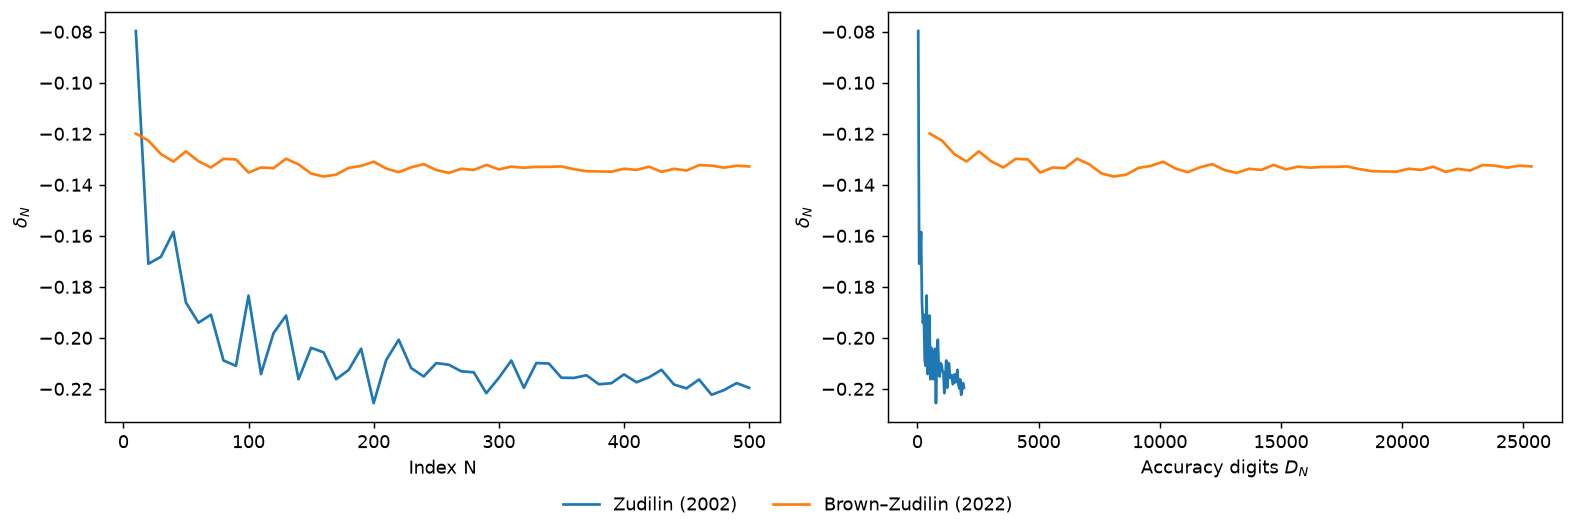

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [13]:
bounds = {
    'Zudilin (2002)': 'Error per index tends to a factor below $1.42521964\\cdot10^{-4}$; no irrationality-measure bound',
    'Brown–Zudilin (2022)': 'Cellular rational approximation construction',
    'New ${}_8F_7(1)$ trajectory': 'Improved local ${}_8F_7(1)$ trajectory',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Zudilin (2002) | Error per index tends to a factor below $1.42521964\cdot10^{-4}$; no irrationality-measure bound | -0.219575829822 (N = 500) |
| Brown–Zudilin (2022) | Cellular rational approximation construction | -0.132809517641 (N = 500) |
| New ${}_8F_7(1)$ trajectory | Improved local ${}_8F_7(1)$ trajectory | Not computed |